Quickly verify that the functions you move into the package behave as expected (`import proteosim as ps` and call the new function).
   - Assemble the final streamlined proteomics workflow you will later share with your peers.
   - Provide the user of your package an example workflow.

In [19]:
import proteosim_max as ps
proteins = ps.read_fasta("../data/sample_proteins.fasta")
len(proteins)

3

In [28]:
peptides = ps.digest_protein_collection(proteins, ps.enzyme_cleavage_patterns["Trypsin"])
sample_protein = proteins["P11802"]
sample_protein_peptides = peptides["P11802"]

In [29]:
import sys
from pathlib import Path

for _path in sys.path:
    print(_path)

/home/mksku/miniforge3/envs/advanced-python_course/lib/python310.zip
/home/mksku/miniforge3/envs/advanced-python_course/lib/python3.10
/home/mksku/miniforge3/envs/advanced-python_course/lib/python3.10/lib-dynload

/home/mksku/miniforge3/envs/advanced-python_course/lib/python3.10/site-packages


Protein digestion

In [30]:
import proteosim_max as ps
protein_map = ps.read_fasta('../data/sample_proteins.fasta')

protein_map

ps.enzyme_cleavage_patterns
print(ps.enzyme_cleavage_patterns)
ps.digest_protein_sequence(protein_map["P11802"], ps.enzyme_cleavage_patterns['LysC'])
ps.digest_protein_collection(protein_map, ps.enzyme_cleavage_patterns['LysC'])


{'LysC': '(?<=K)', 'LysN': '(?=K)', 'ArgC': '(?<=R)', 'Trypsin': '(?<=[KR])(?!P)'}


{'P11802': ['MATSRYEPVAEIGVGAYGTVYK',
  'ARDPHSGHFVALK',
  'VTLVFEHVDQDLRTYLDK',
  'APPPGLPAETIK',
  'DLMRQFLRGLDFLHANCIVHRDLK',
  'PENILVTSGGTVK',
  'PLFCGNSEADQLGK',
  'RISAFRALQHSYLHK',
  'DEGNPE'],
 'A0A087WTH1': ['MEDEEK', 'AEERHK', 'AGRSEEAVRWGARARK'],
 'A0A087WTH5': ['MVIEWERPRMILSNTTAVTPFLTK',
  'LWQETVQQGGNMSGLARRSPRSGDGK',
  'LEALYVLMVLGFFGFFTLGIMLSYIRSK',
  'LEHSNDPFNVYIESNAWQEK']}

In [31]:
ps.digest_protein_collection(protein_map, ps.enzyme_cleavage_patterns['LysC'])


{'P11802': ['MATSRYEPVAEIGVGAYGTVYK',
  'ARDPHSGHFVALK',
  'VTLVFEHVDQDLRTYLDK',
  'APPPGLPAETIK',
  'DLMRQFLRGLDFLHANCIVHRDLK',
  'PENILVTSGGTVK',
  'PLFCGNSEADQLGK',
  'RISAFRALQHSYLHK',
  'DEGNPE'],
 'A0A087WTH1': ['MEDEEK', 'AEERHK', 'AGRSEEAVRWGARARK'],
 'A0A087WTH5': ['MVIEWERPRMILSNTTAVTPFLTK',
  'LWQETVQQGGNMSGLARRSPRSGDGK',
  'LEALYVLMVLGFFGFFTLGIMLSYIRSK',
  'LEHSNDPFNVYIESNAWQEK']}

In [32]:
cleave_pattern = ps.enzyme_cleavage_patterns['Trypsin']

digested_peptides_map = ps.digest_protein_collection(
    protein_map,
    cleave_pattern=cleave_pattern,
    min_pep_len=5,
    max_pep_len=30,
)

digested_peptides_map

{'P11802': ['MATSR',
  'YEPVAEIGVGAYGTVYK',
  'DPHSGHFVALK',
  'VPNGGGGGGGLPISTVR',
  'EVALLR',
  'LEAFEHPNVVR',
  'LMDVCATSR',
  'VTLVFEHVDQDLR',
  'TYLDK',
  'APPPGLPAETIK',
  'GLDFLHANCIVHR',
  'DLKPENILVTSGGTVK',
  'LADFGLAR',
  'IYSYQMALTPVVVTLWYR',
  'APEVLLQSTYATPVDMWSVGCIFAEMFR',
  'KPLFCGNSEADQLGK',
  'IFDLIGLPPEDDWPR',
  'DVSLPR',
  'GAFPPR',
  'GPRPVQSVVPEMEESGAQLLLEMLTFNPHK',
  'ISAFR',
  'ALQHSYLHK',
  'DEGNPE'],
 'A0A087WTH1': ['MEDEEK',
  'AVEILGNTEAAHPPSPIR',
  'CCWLR',
  'CLAATSIICGCSCLGVMALVFAIK',
  'SEEAVR'],
 'A0A087WTH5': ['MVIEWERPR',
  'MILSNTTAVTPFLTK',
  'LWQETVQQGGNMSGLAR',
  'SGDGK',
  'LEALYVLMVLGFFGFFTLGIMLSYIR',
  'LEHSNDPFNVYIESNAWQEK',
  'AYVQAR',
  'VLESYR',
  'SCYVVENHLAIEQPNTHLPETKPSP']}

In [33]:
ps.compute_sequence_coverage(protein_map["P11802"],digested_peptides_map["P11802"])

92.73927392739274

### Liquid Chromatography

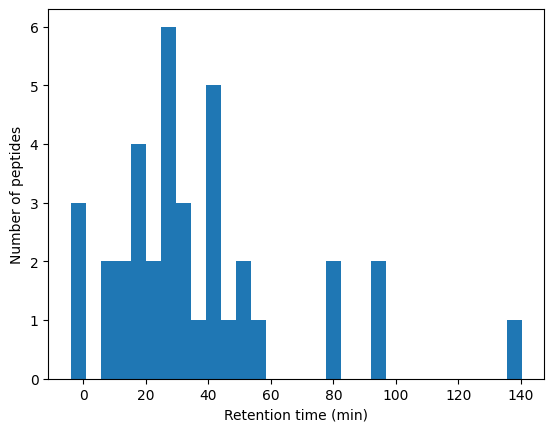

['TYLDK', 'SEEAVR', 'MATSR', 'GAFPPR', 'ISAFR', 'VLESYR', 'DVSLPR', 'AYVQAR']

In [34]:
import proteosim_max as ps
#import matplotlib.pyplot as plt
pooled_peptides = list(set().union(*digested_peptides_map.values()))


ps.predict_lc_retention_times(pooled_peptides)
ps.plot_retention_time(ps.predict_lc_retention_times(pooled_peptides).values(), resolution=30)
ps.select_retention_time_window(ps.predict_lc_retention_times(pooled_peptides), lower_ret_time=0, upper_ret_time=20)

### Mass spectra_simulation

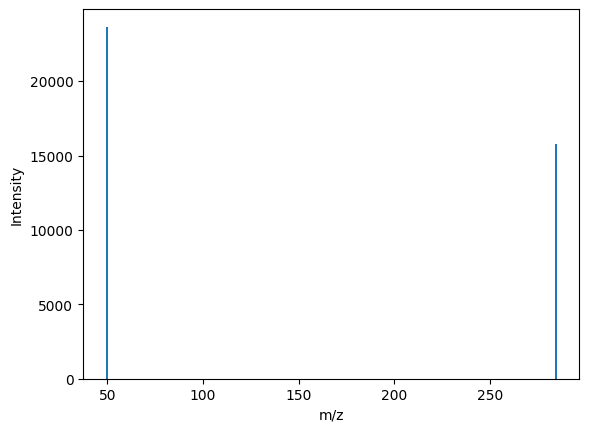

In [44]:
import proteosim_max as ps


amino_acid_mass_dalton = {
    'A': 71.08, 'R': 156.19, 'N': 114.10, 'D': 115.09,
    'C': 103.15, 'E': 129.12, 'Q': 128.13, 'G': 57.05,
    'H': 137.14, 'I': 113.16, 'L': 113.16, 'K': 128.17,
    'M': 131.19, 'F': 147.18, 'P': 97.12, 'S': 87.08,
    'T': 101.11, 'W': 186.21, 'Y': 163.18, 'V': 99.13,
}

ps.calculate_mol_mass(protein_map["P11802"], amino_acid_mass_dict= amino_acid_mass_dalton)
ps.calculate_mol_mass_collection(peptides, amino_acid_mass_dict=amino_acid_mass_dalton)

mass_peptide_map = ps.calculate_mol_mass_collection(peptides, amino_acid_mass_dict=amino_acid_mass_dalton)
ps.calculate_mz_collection(mass_peptide_map, charge = 2)
mz_values = ps.calculate_mz_collection(mass_peptide_map, charge = 2)
ps.plot_spectrum(mz_values)

#ps.fragment_peptide()
# mz2_map = calculate_mz_collection(mass_map_ms2, charge = 1)
# ps.plot_spectrum(mz2_map)